# JS07: Lab 3

Klasterisasi untuk kompresi warna citra.

## Langkah 0: Import library

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Langkah 1: Load citra

Gambar flower.jpg tersedia di dalam Scikit Learn sehingga tidak memerlukan unggahan gambar.

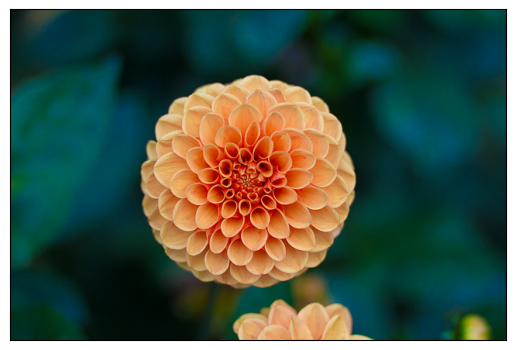

In [2]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)

In [3]:
from pathlib import Path
from shutil import copyfile
import sklearn.datasets

image_path = Path('data/flower.jpg')
image_path.parent.mkdir(parents=True, exist_ok=True)
if not image_path.exists():
    sample_path = Path(sklearn.datasets.__file__).parent / 'images' / 'flower.jpg'
    copyfile(sample_path, image_path)

## Langkah 2: Preprocessing

In [4]:
print(flower.shape)

data = flower / 255.0

data = data.reshape(427 * 640, 3)

print(data.shape)

(427, 640, 3)
(273280, 3)


## Langkah 3: Sebaran warna

In [5]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T
    
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

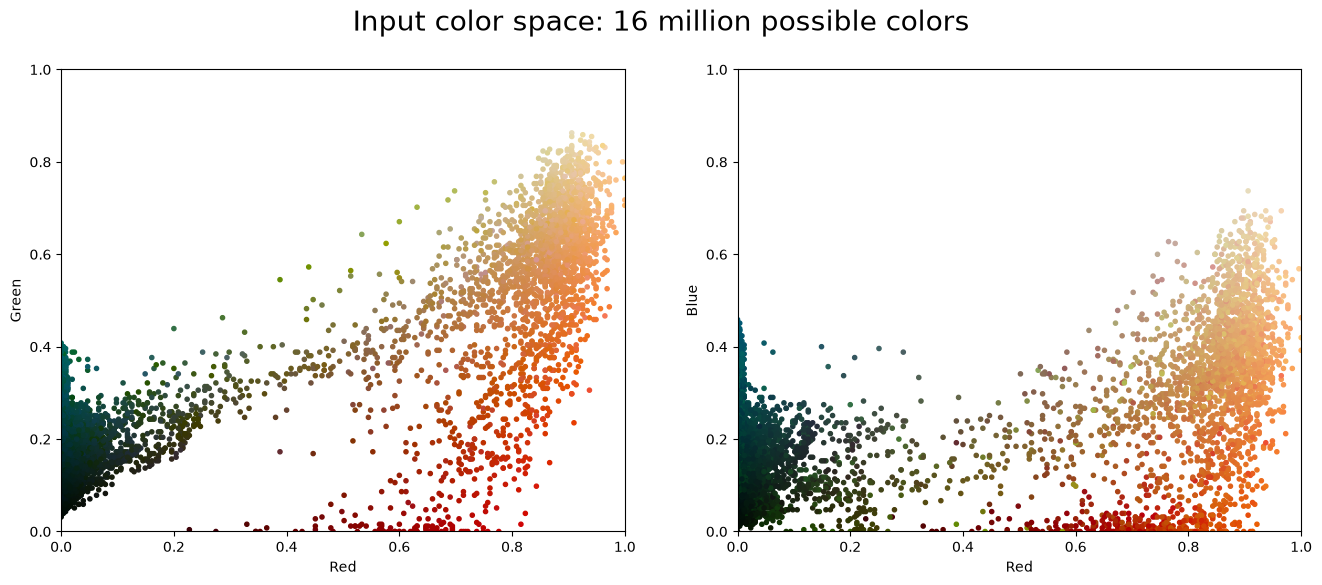

In [6]:
plot_pixels(data, title='Input color space: 16 million possible colors')

## Langkah 4: Klasterisasi menjadi 16 warna

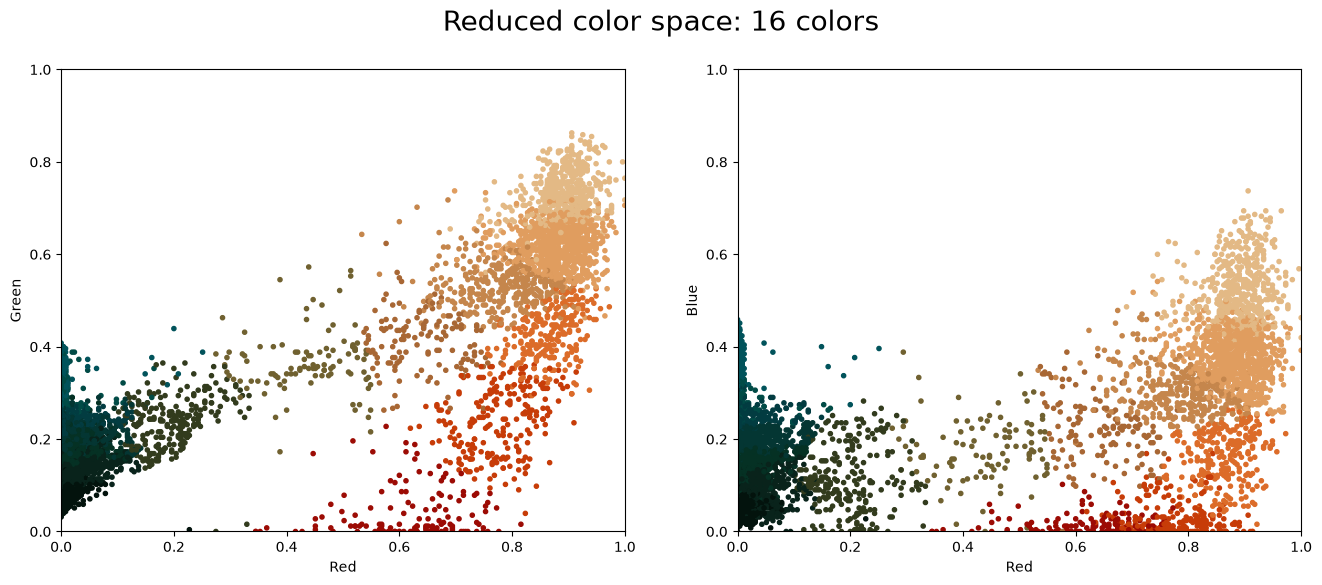

In [7]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

## Perbandingan citra

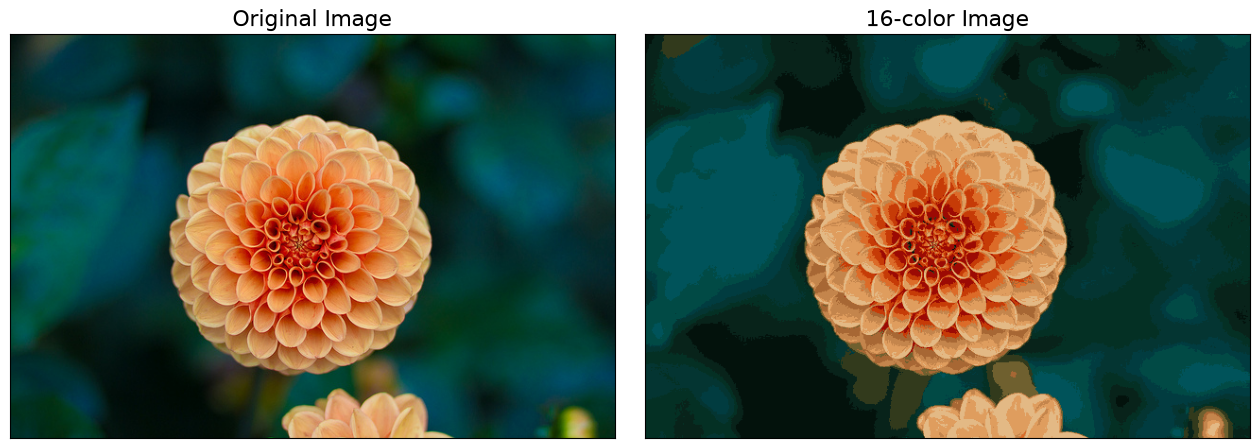

In [8]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

In [9]:
print('Ukuran citra hasil:', flower_recolored.shape)
print('Jumlah warna hasil:', np.unique(new_colors, axis=0).shape[0])

Ukuran citra hasil: (427, 640, 3)


Jumlah warna hasil: 16


## Analisis

Ukuran citra tetap 427 × 640 piksel dengan tiga kanal warna. Warna setiap piksel diganti centroid terdekat sehingga palet hasil hanya berisi 16 warna. Detail warna berkurang, tetapi bentuk bunga masih terlihat. Besar file tersimpan bergantung pada format dan cara penyimpanannya. Palet bisa berbeda setiap eksekusi karena model pada panduan tidak memakai random state.